In [1]:
# Import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.tree import export_graphviz
from IPython.display import Image
from subprocess import call

In [2]:
# Load the titanic dataset
titanic_df = pd.read_csv("titanic.csv")
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Print Information about the DataFrame
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
# Drop the 'Name','Ticket','Cabin','Embarked' column, as it's not needed for analysis. You can also drop other columns as necessary.
titanic_df.drop(["Name","Ticket","Cabin","Embarked"], axis=1, inplace=True)

# Fill missing Age values with the median age
titanic_df["Age"] = titanic_df["Age"].fillna(titanic_df["Age"].median())

In [5]:
# Return unique values from the Sex column
titanic_df["Sex"].unique()

array(['male', 'female'], dtype=object)

In [6]:
# Apply one-hot encoding to the 'Sex' column
titanic_df = pd.get_dummies(titanic_df, prefix="Sex", columns=["Sex"])

# Remove one of the two dummy variables
titanic_df.drop("Sex_female", axis=1, inplace=True)

titanic_df.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male
0,1,0,3,22.0,1,0,7.2500,True
1,2,1,1,38.0,1,0,71.2833,False
2,3,1,3,26.0,0,0,7.9250,False
3,4,1,1,35.0,1,0,53.1000,False
4,5,0,3,35.0,0,0,8.0500,True


Now, we do the same to the "Embarked" column.

In [7]:
# Assign feature data and target labels from the titanic dataset
X = titanic_df.drop(columns=['Survived'])
y = titanic_df['Survived']

# Split data into training and testing sets (70% train, 10% development, 20% test)

# First: 80% temporary, 20% test
X_train_dev, X_test, y_train_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=49
)

# Second: split the remaining 80% into 70% train and 10% dev
# 20/80 = 0.25
X_train, X_dev, y_train, y_dev = train_test_split(
    X_train_dev, y_train_dev, test_size=0.25, random_state=49
)

In [8]:
# Train a Decision Tree Classifier without pruning (max_depth=None)
train_tree = DecisionTreeClassifier(max_depth=None, random_state=49)

# Fit the model to the training data
train_tree.fit(X_train, y_train)

# Training accuracy
train_accuracy = train_tree.score(X_train, y_train)
print(f"Training Accuracy: {round(train_accuracy,2)}")

Training Accuracy: 1.0


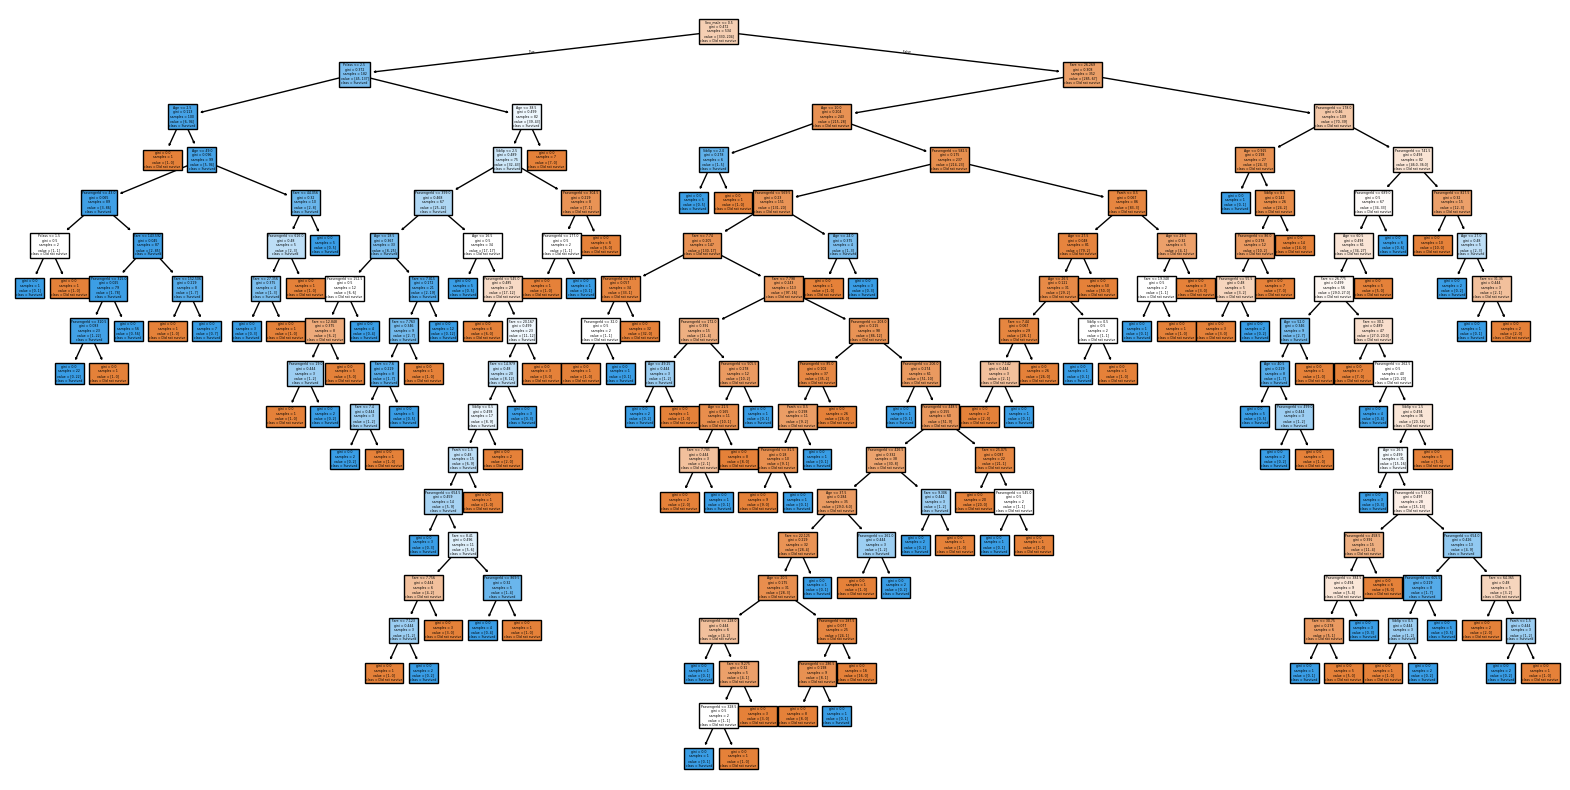

In [9]:
# Plot the accuracy scores against the pruning depths
plt.figure(figsize=(20,10))
plot_tree(train_tree, feature_names=X_train.columns, class_names=["Did not survive", "Survived"], filled=True)
plt.show()

In [10]:
dev_accuracy = train_tree.score(X_dev, y_dev)
print(f"Development Accuracy: {round(dev_accuracy,2)}")

Development Accuracy: 0.72


In [11]:
# Train a Decision Tree Classifier without pruning (max_depth=None)
dev_tree = DecisionTreeClassifier(max_depth=11, random_state=49)

# Fit the model to the training data
dev_tree.fit(X_dev, y_dev)
print("Performance without pruning:", dev_tree.score(X_dev, y_dev))

Performance without pruning: 1.0


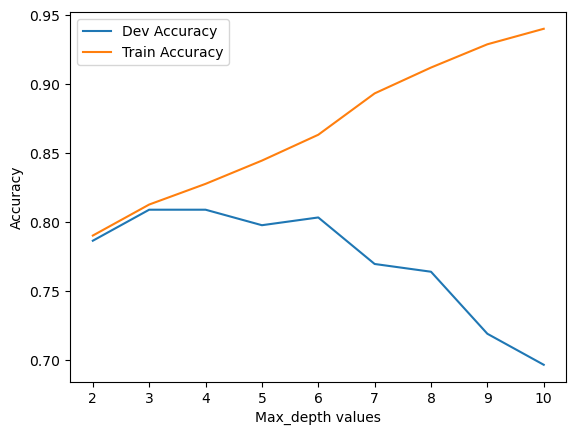

In [12]:
# Define the range of pruning depths
prune_depths = range(2,11)

prune_train_scores = []
prune_dev_scores = []

# Loop through each depth value to evaluate the model's performance
for d in prune_depths:
    clf_train = DecisionTreeClassifier(max_depth=d, random_state=4)
    clf_train.fit(X_train, y_train)

    # Calculate the accuracy of the model on the test set and append it to the list
    dev_score = clf_train.score(X_dev, y_dev)
    prune_dev_scores.append(dev_score)

    train_score = clf_train.score(X_train, y_train)
    prune_train_scores.append(train_score)

# Plot the accuracy scores against the pruning depths
fig, ax = plt.subplots()
ax.plot(prune_depths, prune_dev_scores, label="Dev Accuracy")
ax.plot(prune_depths, prune_train_scores, label="Train Accuracy")
plt.xlabel("Max_depth values")
plt.ylabel("Accuracy")
ax.legend()
plt.show()

As max_depth increases, the dev accuracy generally increases because the decision tree becomes more complex and is able to fit the training data more closely.

At lower depths, the tree is simpler and may underfit the data. As the depth increases, the development accuracy improves as the model is able to capture more useful patterns.

The difference between training and development accuracy becomes larger with max_depth. This indicates that the model is becoming more complex and is increasingly fitting the training data rather than generalising to unseen data. This is a sign of overfitting.

Therefore, the optimal max_depth should be selected based on the development-set performance rather than simply choosing the deepest tree or the model with the highest training accuracy.An optimal would be 3-4 striking a balance between underfitting and overfitting whilst having a simple model.


In [13]:
# Find the best depth by identifying the index of the maximum score
best_depth = prune_depths[np.argmax(prune_dev_scores)]
print('Best performance reached at depth of:', best_depth)

# Create and fit a new Decision Tree Classifier using the best depth found
prune_dev = DecisionTreeClassifier(max_depth=best_depth)
prune_dev.fit(X_dev, y_dev)

Best performance reached at depth of: 3


,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [14]:
# Train the final model using the selected depth

final_model = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=49
)

final_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,49
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [15]:
# Evaluate the final model on the test set

final_test_accuracy = final_model.score(X_test, y_test)

print(f"Final Test Accuracy: {round(final_test_accuracy,3)}")

Final Test Accuracy: 0.804
